In [1]:
import tensorflow as tf

tf.random.set_seed(1) # fixa a semente para resultados consistentes
print("Num GPUs Available: ", len(tf.config.list_physical_devices('GPU'))) # confirma se a GPU está disponível

Num GPUs Available:  1


In [2]:
from tensorflow.keras.datasets import fashion_mnist

(x_train, y_train), (x_test, y_test) = fashion_mnist.load_data() # carrega o Fashion MNIST (60k de treino e 10k de teste)

In [3]:
import numpy as np

dataset = np.concatenate([x_train, x_test], axis=0) # junta treino e teste

# adiciona o canal (28x28x1) e normaliza de [0,255] para [0,1]
dataset = np.expand_dims(dataset, -1).astype("float32") / 255

In [4]:
BATCH_SIZE = 64  # tamanho do lote

# garante o formato (N, 28, 28, 1); é redundante
dataset = np.reshape(dataset, (-1, 28, 28, 1))
dataset = tf.data.Dataset.from_tensor_slices(dataset)
dataset = dataset.shuffle(buffer_size=1024).batch(BATCH_SIZE) # embaralha e agrupa em lotes, sem batch, leria uma imagem por vez

In [5]:
from tensorflow import keras
from tensorflow.keras import layers

NOISE_DIM = 150

generator = keras.models.Sequential([
  keras.layers.InputLayer(input_shape=(NOISE_DIM,)),  # recebe o ruído de 150 dimensões
  layers.Dense(7*7*256),  # projeta o ruído para 7x7x256
  layers.Reshape(target_shape=(7, 7, 256)),  # transforma em mapa de características
  layers.Conv2DTranspose(256, 3, activation="leaky_relu", strides=2, padding="same"),
  layers.Conv2DTranspose(128, 3, activation="leaky_relu", strides=2, padding="same"),
  layers.Conv2DTranspose(1, 3, activation="sigmoid", padding="same")  # 1 canal, pixels em [0,1]
])
generator.summary()  # mostra as camadas e os parâmetros


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/input_layer.py:27: UserWarning: Argument `input_shape` is deprecated. Use `shape` instead.
  warnings.warn(


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 12544)          │     1,894,144 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape (Reshape)               │ (None, 7, 7, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose                │ (None, 14, 14, 256)    │       590,080 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_1              │ (None, 28, 28, 128)    │       295,040 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_2              │ (None, 28, 28, 1)      │         1,153 │
│ (Conv2DTranspose)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,780,417 (10.61 MB)

 Trainable params: 2,780,417 (10.61 MB)

 Non-trainable params: 0 (0.00 B)

In [6]:
# discriminador com camadas de downsampling
discriminator = keras.models.Sequential([
  keras.layers.InputLayer(input_shape=(28, 28, 1)),  # recebe uma imagem 28x28x1
  layers.Conv2D(256, 3, activation="relu", strides=2, padding="same"),
  layers.Conv2D(128, 3, activation="relu", strides=2, padding="same"),
  layers.Flatten(),  # achata para vetor
  layers.Dense(64, activation="relu"),  # camada densa intermediária
  layers.Dropout(0.2),  # dropout para reduzir overfitting
  layers.Dense(1, activation="sigmoid")  # probabilidade de ser real
])

discriminator.summary()  # mostra as camadas e os parâmetros

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 14, 14, 256)    │         2,560 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 7, 7, 128)      │       295,040 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │       401,472 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 699,137 (2.67 MB)

 Trainable params: 699,137 (2.67 MB)

 Non-trainable params: 0 (0.00 B)

In [7]:
# taxas de aprendizado altas prejudicam muito a estabilidade
optimizerG = keras.optimizers.Adam(learning_rate=0.00001, beta_1=0.5)  # gerador: lr menor
optimizerD = keras.optimizers.Adam(learning_rate=0.00003, beta_1=0.5)  # discriminador: lr 3x maior

# classificador binário (real ou falso)
lossFn = keras.losses.BinaryCrossentropy(from_logits=True)  # espera logits, mas o discriminador já aplica sigmoid

# métricas de acurácia
gAccMetric = tf.keras.metrics.BinaryAccuracy()  # quantas vezes o gerador engana o discriminador
dAccMetric = tf.keras.metrics.BinaryAccuracy()  # quantas vezes o discriminador acerta

In [8]:
# o decorador compila a função em grafo do TensorFlow, deixando-a mais rápida
@tf.function
def trainDStep(data):
  batchSize = tf.shape(data)[0]
  noise = tf.random.normal(shape=(batchSize, NOISE_DIM))

  # junta os rótulos reais e falsos
  y_true = tf.concat(
    [
      # os dados originais são reais, rótulo 1
      tf.ones(batchSize, 1),
      # os dados gerados são falsos, rótulo 0
      tf.zeros(batchSize, 1)
    ],
    axis=0
  )

  # registra as operações para calcular os gradientes
  with tf.GradientTape() as tape:
    fake = generator(noise) # gera amostras falsas
    x = tf.concat([data, fake], axis=0) # junta dados reais e falsos
    y_pred = discriminator(x) # o discriminador tenta separá-los

    discriminatorLoss = lossFn(y_true, y_pred) # calcula a perda

  # retropropagação e atualização dos pesos (só do discriminador)
  grads = tape.gradient(discriminatorLoss, discriminator.trainable_weights)
  optimizerD.apply_gradients(zip(grads, discriminator.trainable_weights))

  # atualiza a acurácia
  dAccMetric.update_state(y_true, y_pred)

  # devolve a perda para acompanhamento
  return {
      "discriminator_loss": discriminatorLoss,
      "discriminator_accuracy": dAccMetric.result()
  }

In [9]:
@tf.function
def trainGStep(data):
  batchSize = tf.shape(data)[0]  # tamanho do lote
  noise = tf.random.normal(shape=(batchSize, NOISE_DIM))  # novo ruído
  y_true = tf.ones(batchSize, 1)  # rótulo "real" para as imagens falsas

  with tf.GradientTape() as tape:
    y_pred = discriminator(generator(noise))  # gera e passa pelo discriminador
    generatorLoss = lossFn(y_true, y_pred)  # perda: quão longe está de enganar

  grads = tape.gradient(generatorLoss, generator.trainable_weights)  # gradientes só do gerador
  optimizerG.apply_gradients(zip(grads, generator.trainable_weights))  # atualiza o gerador

  gAccMetric.update_state(y_true, y_pred)  # taxa de vezes que enganou o discriminador

  return {
      "generator_loss": generatorLoss,
      "generator_accuracy": gAccMetric.result()
  }

In [10]:
from matplotlib import pyplot as plt


def plotImages(model):
    images = model(np.random.normal(size=(81, NOISE_DIM)))  # gera 81 imagens a partir de ruído
    plt.figure(figsize=(9, 9))

    for i, image in enumerate(images):
        plt.subplot(9,9,i+1)
        plt.imshow(np.squeeze(image, -1), cmap="Greys_r")  # remove o canal e mostra em cinza
        plt.axis('off')

    plt.show();

In [11]:
for epoch in range(30):  # 30 épocas

  # acumuladores para calcular a média no fim da época
  dLossSum = 0
  gLossSum = 0
  dAccSum = 0
  gAccSum = 0
  cnt = 0

  # percorre o dataset um lote por vez
  for batch in dataset:

    # treina o discriminador
    dLoss = trainDStep(batch)
    dLossSum += dLoss['discriminator_loss']
    dAccSum += dLoss['discriminator_accuracy']

    # treina o gerador
    gLoss = trainGStep(batch)
    gLossSum += gLoss['generator_loss']
    gAccSum += gLoss['generator_accuracy']

    cnt += 1

  # mostra o desempenho da época
  print("E:{}, Loss G:{:0.4f}, Loss D:{:0.4f}, Acc G:%{:0.2f}, Acc D:%{:0.2f}".format(
      epoch,
      gLossSum/cnt,
      dLossSum/cnt,
      100 * gAccSum/cnt,
      100 * dAccSum/cnt
  ))

  if epoch % 2 == 0:  # a cada 2 épocas, mostra amostras
    plotImages(generator)

Output hidden; open in https://colab.research.google.com to view.

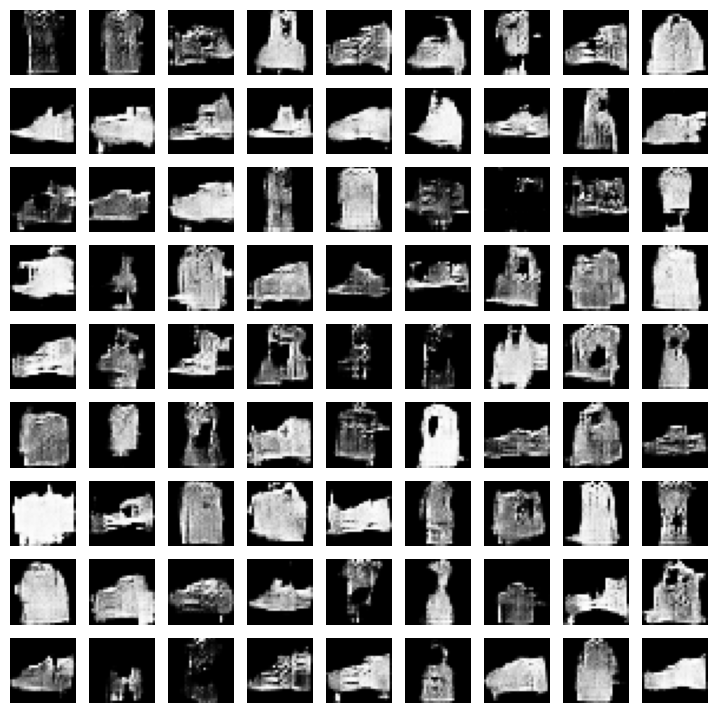

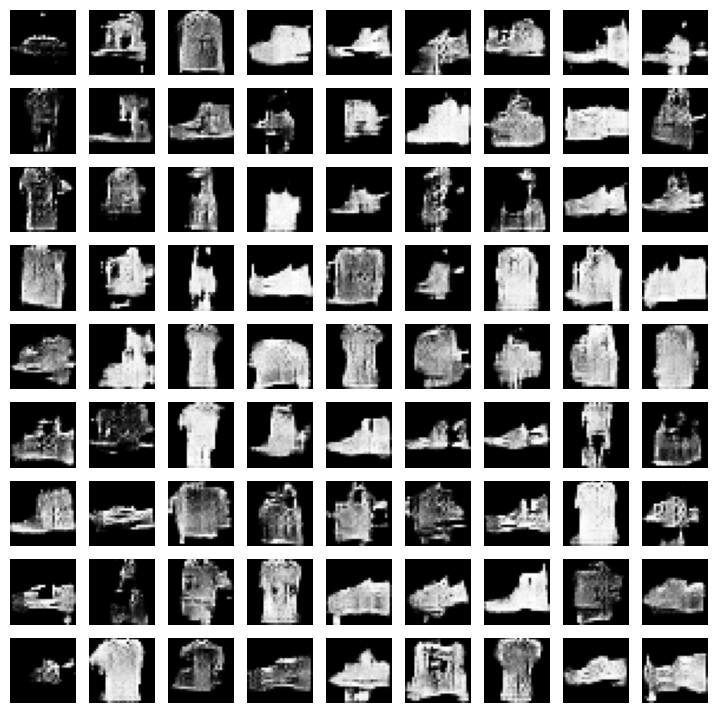

In [13]:
# gera imagens com o modelo treinado
images = generator(np.random.normal(size=(81, NOISE_DIM)))  # 81 vetores de ruído

# plota as amostras geradas
from matplotlib import pyplot as plt

plt.figure(figsize=(9, 9))

for i, image in enumerate(images):
    plt.subplot(9,9,i+1)
    plt.imshow(np.squeeze(image, -1), cmap="Greys_r")  # mostra em cinza
    plt.axis('off')

plt.show();